In [1]:
!pip install -q opencv-python-headless matplotlib numpy


In [2]:
import os
import urllib.request

# Create a folder for the model
os.makedirs("models", exist_ok=True)

# YuNet pretrained face detection model
model_url = (
    "https://github.com/opencv/opencv_zoo/raw/main/"
    "models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
)

model_path = "models/face_detection_yunet_2023mar.onnx"

urllib.request.urlretrieve(model_url, model_path)

print("Model downloaded successfully!")
print("Model location:", model_path)
print("Model size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

Model downloaded successfully!
Model location: models/face_detection_yunet_2023mar.onnx
Model size: 227.14 KB


In [3]:
import cv2
import os

model_path = "models/face_detection_yunet_2023mar.onnx"

assert os.path.exists(model_path), "Model file not found!"

print("OpenCV version:", cv2.__version__)
print("Model available:", os.path.exists(model_path))
print("Setup completed successfully!")

OpenCV version: 4.14.0
Model available: True
Setup completed successfully!


In [4]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload an image
uploaded = files.upload()

# Get the uploaded image filename
image_path = next(iter(uploaded))

# Load the image
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not load the image. Please upload a valid image.")

# Load the YuNet face detection model
model_path = "models/face_detection_yunet_2023mar.onnx"

height, width = image.shape[:2]

detector = cv2.FaceDetectorYN.create(
    model_path,
    "",
    (width, height),
    0.6,   # Confidence threshold
    0.3,   # NMS threshold
    5000  # Maximum number of detections
)

# Detect faces
_, faces = detector.detect(image)

# Draw bounding boxes around detected faces
face_count = 0

if faces is not None:
    for face in faces:
        x, y, w, h = map(int, face[:4])

        # Draw rectangle
        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        # Display confidence score
        confidence = face[-1]

        cv2.putText(
            image,
            f"Face: {confidence:.2f}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        face_count += 1

# Convert BGR to RGB for displaying with Matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.title(f"Face Detection Results: {face_count} face(s)")
plt.show()

print("Total faces detected:", face_count)

KeyboardInterrupt: 

In [1]:
import urllib.request

image_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"

urllib.request.urlretrieve(image_url, "sample_face.jpg")

print("Sample image downloaded successfully!")

Sample image downloaded successfully!


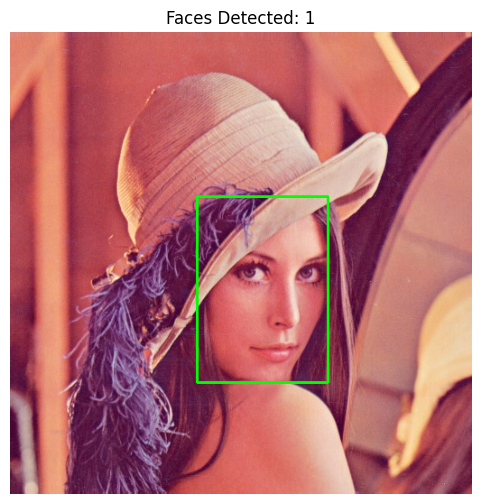

Total faces detected: 1


In [2]:
import cv2
import matplotlib.pyplot as plt

# Load the sample image
image = cv2.imread("sample_face.jpg")

if image is None:
    raise FileNotFoundError("Image not found. Run the previous cell first!")

# Get image dimensions
height, width = image.shape[:2]

# Load the pretrained YuNet face detector
model_path = "models/face_detection_yunet_2023mar.onnx"

detector = cv2.FaceDetectorYN.create(
    model_path,
    "",
    (width, height),
    0.6,   # Confidence threshold
    0.3,   # NMS threshold
    5000   # Maximum detections
)

# Detect faces
_, faces = detector.detect(image)

face_count = 0

# Draw rectangles around detected faces
if faces is not None:
    for face in faces:
        x, y, w, h = map(int, face[:4])

        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        face_count += 1

# Display the result
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Faces Detected: {face_count}")
plt.show()

print("Total faces detected:", face_count)


In [4]:
import urllib.request

video_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/vtest.avi"

urllib.request.urlretrieve(video_url, "sample_video.avi")

print("✅ Sample video downloaded successfully!")

✅ Sample video downloaded successfully!


In [5]:
import cv2

# Open the downloaded video
video = cv2.VideoCapture("sample_video.avi")

if not video.isOpened():
    raise RuntimeError("Could not open the video!")

# Get video properties
width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = video.get(cv2.CAP_PROP_FPS)

print(f"Video resolution: {width} x {height}")
print(f"Frames per second: {fps:.2f}")

# Create output video
output = cv2.VideoWriter(
    "face_detection_output.mp4",
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps if fps > 0 else 20,
    (width, height)
)

# Load pretrained YuNet face detector
detector = cv2.FaceDetectorYN.create(
    "models/face_detection_yunet_2023mar.onnx",
    "",
    (width, height),
    0.6,
    0.3,
    5000
)

frame_count = 0
frames_with_faces = 0
total_faces = 0

while True:
    ret, frame = video.read()

    if not ret:
        break

    # Detect faces in the current frame
    _, faces = detector.detect(frame)
    frame_count += 1

    if faces is not None:
        frames_with_faces += 1
        total_faces += len(faces)

        # Draw a rectangle around each detected face
        for face in faces:
            x, y, w, h = map(int, face[:4])

            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            confidence = face[14]
            cv2.putText(
                frame,
                f"Face: {confidence:.2f}",
                (x, max(20, y - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    output.write(frame)

video.release()
output.release()

print("\nFace Detection Completed!")
print("Total frames processed:", frame_count)
print("Frames containing detected faces:", frames_with_faces)
print("Total face detections across all frames:", total_faces)
print("Output video: face_detection_output.mp4")

Video resolution: 768 x 576
Frames per second: 10.00

Face Detection Completed!
Total frames processed: 795
Frames containing detected faces: 439
Total face detections across all frames: 636
Output video: face_detection_output.mp4


In [6]:
from IPython.display import Video, display

display(Video("face_detection_output.mp4", embed=True))

In [7]:
!pip install -q gradio


In [8]:
import gradio as gr
import cv2
import os
import tempfile

MODEL_PATH = "models/face_detection_yunet_2023mar.onnx"


def detect_faces_image(image):
    if image is None:
        return None, "Please upload an image."

    # Gradio provides the image in RGB format
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    height, width = image.shape[:2]

    detector = cv2.FaceDetectorYN.create(
        MODEL_PATH, "", (width, height), 0.6, 0.3, 5000
    )

    _, faces = detector.detect(image)
    count = 0

    if faces is not None:
        count = len(faces)

        for face in faces:
            x, y, w, h = map(int, face[:4])

            cv2.rectangle(
                image, (x, y), (x + w, y + h), (0, 255, 0), 2
            )

            confidence = float(face[-1])
            cv2.putText(
                image,
                f"{confidence:.2f}",
                (x, max(20, y - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

    result = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return result, f"Faces detected: {count}"


def detect_faces_video(video_path):
    if video_path is None:
        return None, "Please upload a video."

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return None, "Could not open the video."

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    if width <= 0 or height <= 0:
        cap.release()
        return None, "Invalid video dimensions."

    if fps <= 0:
        fps = 20

    detector = cv2.FaceDetectorYN.create(
        MODEL_PATH, "", (width, height), 0.6, 0.3, 5000
    )

    output_path = tempfile.mktemp(suffix=".mp4")
    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    frame_count = 0
    frames_with_faces = 0
    total_detections = 0

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        _, faces = detector.detect(frame)
        frame_count += 1

        if faces is not None:
            frames_with_faces += 1
            total_detections += len(faces)

            for face in faces:
                x, y, w, h = map(int, face[:4])

                cv2.rectangle(
                    frame, (x, y), (x + w, y + h), (0, 255, 0), 2
                )

        writer.write(frame)

    cap.release()
    writer.release()

    if frame_count == 0:
        return None, "No video frames could be read."

    stats = (
        f"Frames processed: {frame_count}\n"
        f"Frames containing faces: {frames_with_faces}\n"
        f"Total face detections across frames: {total_detections}\n"
        f"Percentage of frames with detections: "
        f"{frames_with_faces / frame_count * 100:.2f}%"
    )

    return output_path, stats


with gr.Blocks(title="Face Detection System") as app:
    gr.Markdown("# Face Detection System")
    gr.Markdown(
        "Detect faces in images and videos using OpenCV and the "
        "pretrained YuNet face-detection model."
    )

    with gr.Tab("Image Detection"):
        image_input = gr.Image(type="numpy", label="Upload an image")
        image_button = gr.Button("Detect Faces")
        image_output = gr.Image(label="Detection Result")
        image_stats = gr.Textbox(label="Results")

        image_button.click(
            detect_faces_image,
            inputs=image_input,
            outputs=[image_output, image_stats]
        )

    with gr.Tab("Video Detection"):
        video_input = gr.Video(label="Upload a video")
        video_button = gr.Button("Process Video")
        video_output = gr.Video(label="Processed Video")
        video_stats = gr.Textbox(label="Video Statistics", lines=5)

        video_button.click(
            detect_faces_video,
            inputs=video_input,
            outputs=[video_output, video_stats]
        )

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://63d16f62b5628b7094.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
